# Varying regularization in Multi-layer Perceptron: sklearn vs Moxie

**Reference example:** `../scikit-learn/examples/neural_networks/plot_mlp_alpha.py` at scikit-learn
`4358542a1bd39af2e7e1cbace8b9fed067473c5b`
([rendered gallery page](https://scikit-learn.org/dev/auto_examples/neural_networks/plot_mlp_alpha.html)).

**Scenario:** `make_pipeline(StandardScaler(), MLPClassifier(solver="lbfgs", alpha=alpha, random_state=1,
max_iter=2000, early_stopping=True, hidden_layer_sizes=[10, 10]))` for five `alpha` values on the moons, circles and
a linearly separable dataset, with `predict_proba` decision surfaces and test scores.

**Moxie status:** `MLPClassifier` and `MLPRegressor` are documented raising declarations
(`families/neural_network/docs/scope.md`): construction raises `NotImplementedError` and no forward pass,
backpropagation, loss or solver exists. This notebook runs the reference, runs the part of the pipeline Moxie has
(`StandardScaler` on the same splits, compared numerically), and proves the MLP failure is clear. Every MLP output
is a GAP; nothing is substituted.

**Adaptations:** smaller figure (dpi 60). Datasets are generated in Python and shared.

**Determinism:** deterministic (fixed dataset seeds, `random_state=1`, full-batch L-BFGS).

In [1]:
import sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "notebooks/_support/moxie_nb.py").exists())
sys.path.insert(0, str(ROOT / "notebooks/_support"))
%load_ext moxie_nb
nb = moxie_nb.Session("neural_network/plot_mlp_alpha")

## 1. scikit-learn (Python reference)

The official code; only the figure size/dpi changed.

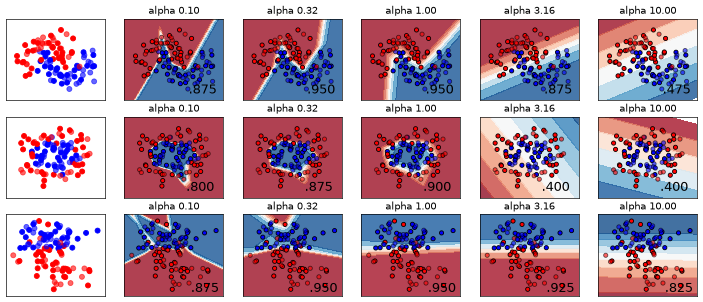

[[0.875 0.95  0.95  0.875 0.475]
 [0.8   0.875 0.9   0.4   0.4  ]
 [0.875 0.95  0.95  0.925 0.825]]


In [2]:
import numpy as np
from matplotlib import pyplot as plt
from matplotlib.colors import ListedColormap

from sklearn.datasets import make_circles, make_classification, make_moons
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

h = 0.02  # step size in the mesh

alphas = np.logspace(-1, 1, 5)

classifiers = []
names = []
for alpha in alphas:
    classifiers.append(
        make_pipeline(
            StandardScaler(),
            MLPClassifier(
                solver="lbfgs",
                alpha=alpha,
                random_state=1,
                max_iter=2000,
                early_stopping=True,
                hidden_layer_sizes=[10, 10],
            ),
        )
    )
    names.append(f"alpha {alpha:.2f}")

X, y = make_classification(
    n_features=2, n_redundant=0, n_informative=2, random_state=0, n_clusters_per_class=1
)
rng = np.random.RandomState(2)
X += 2 * rng.uniform(size=X.shape)
linearly_separable = (X, y)

datasets = [
    make_moons(noise=0.3, random_state=0),
    make_circles(noise=0.2, factor=0.5, random_state=1),
    linearly_separable,
]

figure = plt.figure(figsize=(12, 6), dpi=60)
i = 1
splits, scores, scaled = [], [], []
# iterate over datasets
for X, y in datasets:
    # split into training and test part
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.4, random_state=42
    )
    splits.append((X_train, X_test, y_train, y_test))

    x_min, x_max = X[:, 0].min() - 0.5, X[:, 0].max() + 0.5
    y_min, y_max = X[:, 1].min() - 0.5, X[:, 1].max() + 0.5
    xx, yy = np.meshgrid(np.arange(x_min, x_max, h), np.arange(y_min, y_max, h))

    # just plot the dataset first
    cm = plt.cm.RdBu
    cm_bright = ListedColormap(["#FF0000", "#0000FF"])
    ax = plt.subplot(len(datasets), len(classifiers) + 1, i)
    # Plot the training points
    ax.scatter(X_train[:, 0], X_train[:, 1], c=y_train, cmap=cm_bright)
    # and testing points
    ax.scatter(X_test[:, 0], X_test[:, 1], c=y_test, cmap=cm_bright, alpha=0.6)
    ax.set_xlim(xx.min(), xx.max())
    ax.set_ylim(yy.min(), yy.max())
    ax.set_xticks(())
    ax.set_yticks(())
    i += 1

    # iterate over classifiers
    for name, clf in zip(names, classifiers):
        ax = plt.subplot(len(datasets), len(classifiers) + 1, i)
        clf.fit(X_train, y_train)
        score = clf.score(X_test, y_test)
        scores.append(score)

        # Plot the decision boundary. For that, we will assign a color to each
        # point in the mesh [x_min, x_max] x [y_min, y_max].
        if hasattr(clf, "decision_function"):
            Z = clf.decision_function(np.column_stack([xx.ravel(), yy.ravel()]))
        else:
            Z = clf.predict_proba(np.column_stack([xx.ravel(), yy.ravel()]))[:, 1]

        # Put the result into a color plot
        Z = Z.reshape(xx.shape)
        ax.contourf(xx, yy, Z, cmap=cm, alpha=0.8)

        # Plot also the training points
        ax.scatter(
            X_train[:, 0],
            X_train[:, 1],
            c=y_train,
            cmap=cm_bright,
            edgecolors="black",
            s=25,
        )
        # and testing points
        ax.scatter(
            X_test[:, 0],
            X_test[:, 1],
            c=y_test,
            cmap=cm_bright,
            alpha=0.6,
            edgecolors="black",
            s=25,
        )

        ax.set_xlim(xx.min(), xx.max())
        ax.set_ylim(yy.min(), yy.max())
        ax.set_xticks(())
        ax.set_yticks(())
        ax.set_title(name)
        ax.text(
            xx.max() - 0.3,
            yy.min() + 0.3,
            f"{score:.3f}".lstrip("0"),
            size=15,
            horizontalalignment="right",
        )
        i += 1

figure.subplots_adjust(left=0.02, right=0.98)
plt.show()
print(np.array(scores).reshape(3, 5))
for k, (X_train, X_test, y_train, y_test) in enumerate(splits):
    scaled.append(StandardScaler().fit(X_train).transform(X_test))
    nb.share(**{f"X_train{k}": X_train, f"X_test{k}": X_test})

## 2. Moxie (native Mojo)

The pipeline's first step exists: `StandardScaler` on the same three splits.

In [3]:
%%mojo scaler
from moxie.preprocessing import StandardScaler
from moxie_nb_io import load, save


def main() raises:
    for k in range(3):
        var scaler = StandardScaler()
        _ = scaler.fit(load("X_train" + String(k)))
        save("scaled" + String(k), scaler.transform(load("X_test" + String(k))))

### Unsupported steps

`MLPClassifier` keeps sklearn's constructor signature but raises at construction with a message naming what is
missing:

In [4]:
%%mojo mlp_classifier --expect-fail
from moxie.neural_network import MLPClassifier


def main() raises:
    var clf = MLPClassifier(solver="lbfgs", alpha=0.1, random_state=1, max_iter=2000,
                            early_stopping=True, hidden_layer_sizes=(10, 10))

Expected failure (unsupported in Moxie):
exit status 1
stack trace was not collected. Enable stack trace collection with environment variable `MODULAR_DEBUG=stack-trace-on-error`
Unhandled exception caught during execution: NotImplementedError: MLPClassifier is not implemented in Moxie: forward/backpropagation, the lbfgs/sgd/adam solvers, early stopping, warm start and partial_fit are unfinished (families/neural_network/docs/scope.md)



`MLPRegressor` behaves the same:

In [5]:
%%mojo mlp_regressor --expect-fail
from moxie.neural_network import MLPRegressor


def main() raises:
    var reg = MLPRegressor(hidden_layer_sizes=(10, 10), random_state=1)

Expected failure (unsupported in Moxie):
exit status 1
stack trace was not collected. Enable stack trace collection with environment variable `MODULAR_DEBUG=stack-trace-on-error`
Unhandled exception caught during execution: NotImplementedError: MLPRegressor is not implemented in Moxie: forward/backpropagation, the lbfgs/sgd/adam solvers, early stopping, warm start and partial_fit are unfinished (families/neural_network/docs/scope.md)



The declaration implements no estimator trait, so it cannot be a pipeline step either (compile-time rejection):

In [6]:
%%mojo mlp_pipeline --expect-fail
from moxie.neural_network import MLPClassifier
from moxie.pipeline import make_pipeline
from moxie.preprocessing import StandardScaler


def main() raises:
    var pipe = make_pipeline(StandardScaler(), MLPClassifier(solver="lbfgs"))

Expected failure (unsupported in Moxie):
compilation failed
/home/strgenix/postdoc/projects/mojods/porting-sklearn/moxie/builds/notebooks/neural_network/plot_mlp_alpha/mlp_pipeline.mojo:7:61: error: invalid call to 'make_pipeline': value passed to 'estimator' cannot be converted from 'MLPClassifier' to 'E', argument type 'MLPClassifier' does not conform to trait 'Predictor & SupervisedEstimator & Deinitable'
    var pipe = make_pipeline(StandardScaler(), MLPClassifier(solver="lbfgs"))
               ~~~~~~~~~~~~~                   ~~~~~~~~~~~~~^~~~~~~~~~~~~~~~
Imported from /home/strgenix/postdoc/projects/mojods/porting-sklearn/moxie/builds/notebooks/neural_network/plot_mlp_alpha/mlp_pipeline.mojo:2:
Imported from /home/strgenix/postdoc/projects/mojods/porting-sklearn/moxie/builds/deps/moxie/pipeline.mojo:6:
/home/strgenix/postdoc/projects/mojods/porting-sklearn/moxie/builds/deps/moxie/_pipeline_api.mojo:39:5: note: function declared here
def make_pipeline[P: TransformerMixin & Deinita

## 3. Side by side and parity

In [7]:
mx = nb.results["scaler"]
moxie_nb.side_by_side(sklearn=scaled[0][:5], moxie=mx["scaled0"][:5])
for k, name in enumerate(["moons", "circles", "linearly separable"]):
    nb.compare(f"StandardScaler step ({name})", scaled[k], mx[f"scaled{k}"], rtol=1e-12, atol=1e-14,
               reason="Float64 mean/variance; summation order of 60-sample reductions")
nb.note("MLPClassifier fit/score/predict_proba (15 panels)", "GAP",
        "MLPClassifier is a raising declaration: construction raises 'NotImplementedError: MLPClassifier is not "
        "implemented in Moxie: forward/backpropagation, the lbfgs/sgd/adam solvers, early stopping, warm start and "
        "partial_fit are unfinished' (expected-failure cell above)")
nb.note("MLPRegressor", "GAP", "same raising declaration (expected-failure cell above)")
nb.note("make_pipeline(StandardScaler(), MLPClassifier(...))", "GAP",
        "the declaration implements no estimator trait; make_pipeline rejects it at compile time")
nb.report()
nb.assert_parity()

check,status,sklearn shape,moxie shape,max |diff|,max rel,tolerance,detail,tolerance reason
StandardScaler step (moons),PASS,"(40, 2)","(40, 2)",0,0,"rtol=1e-12, atol=1e-14",,Float64 mean/variance; summation order of 60-sample reductions
StandardScaler step (circles),PASS,"(40, 2)","(40, 2)",0,0,"rtol=1e-12, atol=1e-14",,Float64 mean/variance; summation order of 60-sample reductions
StandardScaler step (linearly separable),PASS,"(40, 2)","(40, 2)",0,0,"rtol=1e-12, atol=1e-14",,Float64 mean/variance; summation order of 60-sample reductions
MLPClassifier fit/score/predict_proba (15 panels),GAP,,,,,,"MLPClassifier is a raising declaration: construction raises 'NotImplementedError: MLPClassifier is not implemented in Moxie: forward/backpropagation, the lbfgs/sgd/adam solvers, early stopping, warm start and partial_fit are unfinished' (expected-failure cell above)",
MLPRegressor,GAP,,,,,,same raising declaration (expected-failure cell above),
"make_pipeline(StandardScaler(), MLPClassifier(...))",GAP,,,,,,the declaration implements no estimator trait; make_pipeline rejects it at compile time,
